In [2]:
# =============================================================================
# MODEL: SIMPLE LINEAR REGRESSION
# Description  : Fits a straight line y = b0 + b1*x using ONE feature.
# Justification: Baseline model. Previous_Score is used because it has the
#                strongest correlation with Final_Score (~0.58).
# =============================================================================
import os, json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
# ---------------------------- 1. IMPORT DATA ---------------------------------
# The workbook has 2 sheets ("Data" and "README"), so the sheet is named
# explicitly. Needs: pip install openpyxl
df = pd.read_excel("C:/Users/hp/Downloads/Data_Practical/student_performance.xlsx")
df = df.drop(columns=["Student_ID"])      # ID only identifies a student, no predictive value
X = df.drop(columns=["Final_Score"])      # 5 features
y = df["Final_Score"]                     # target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------- 2. MODEL ---------------------------------------
model = LinearRegression()
model.fit(X_train[["Previous_Score"]], y_train)

# ---------------------------- 3. EVALUATION ----------------------------------
pred = model.predict(X_test[["Previous_Score"]])
metrics = {
    "Model": "Simple Linear Regression",
    "Train R2": r2_score(y_train, model.predict(X_train[["Previous_Score"]])),
    "Test R2": r2_score(y_test, pred),
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
    "CV R2 (5-fold)": cross_val_score(model, X_train[["Previous_Score"]], y_train, cv=kf, scoring="r2").mean(),
}
print(pd.Series(metrics).to_string())
print(f"Final_Score = {model.intercept_:.2f} + {model.coef_[0]:.3f} * Previous_Score")

os.makedirs("results", exist_ok=True)
json.dump(metrics, open("results/simple_linear_regression.json", "w"))

Model             Simple Linear Regression
Train R2                          0.330441
Test R2                           0.369084
MAE                               6.673647
RMSE                              8.295284
CV R2 (5-fold)                    0.282864
Final_Score = 44.26 + 0.302 * Previous_Score


In [5]:
# =============================================================================
# MODEL: MULTIPLE LINEAR REGRESSION
# Description  : Linear model with several features: y = b0 + b1*x1 + ... + bn*xn.
# Justification: Final_Score depends on several factors (study hours, attendance,
#                previous score...), so using all 5 features should beat the
#                simple model. Coefficients are easy to interpret.
# =============================================================================
import os, json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ---------------------------- 1. IMPORT DATA ---------------------------------
df = pd.read_excel("C:/Users/hp/Downloads/Data_Practical/student_performance.xlsx")
df = df.drop(columns=["Student_ID"])
X = df.drop(columns=["Final_Score"])
y = df["Final_Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------- 2. MODEL ---------------------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# ---------------------------- 3. EVALUATION ----------------------------------
pred = model.predict(X_test)
metrics = {
    "Model": "Multiple Linear Regression",
    "Train R2": r2_score(y_train, model.predict(X_train)),
    "Test R2": r2_score(y_test, pred),
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
    "CV R2 (5-fold)": cross_val_score(model, X_train, y_train, cv=kf, scoring="r2").mean(),
}
print(pd.Series(metrics).to_string())
print(pd.Series(model.coef_, index=X.columns).round(3).to_string())

os.makedirs("results", exist_ok=True)
json.dump(metrics, open("results/multiple_linear_regression.json", "w"))

Model             Multiple Linear Regression
Train R2                            0.858573
Test R2                             0.910232
MAE                                 2.492525
RMSE                                 3.12901
CV R2 (5-fold)                      0.842751
Hours_Studied     1.833
Attendance_Pct    0.268
Previous_Score    0.348
Sleep_Hours       0.748
Practice_Tests    1.016


In [6]:
# =============================================================================
# MODEL: POLYNOMIAL REGRESSION
# Description  : Linear regression on polynomial terms (x, x^2, x1*x2...), so it
#                can fit curves.
# Justification: README says Hours_Studied has diminishing returns (curved) and
#                Sleep_Hours is best around 7 hours (inverted U). A straight line
#                cannot capture that, degree 2 can. Scaling keeps terms comparable.
# =============================================================================
import os, json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
---------------------------------
df = pd.read_excel("C:/Users/hp/Downloads/Data_Practical/student_performance.xlsx")
df = df.drop(columns=["Student_ID"])
X = df.drop(columns=["Final_Score"])
y = df["Final_Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
# ---------------------------- 2. MODEL ---------------------------------------
model = make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                      StandardScaler(),
                      LinearRegression())
model.fit(X_train, y_train)
# ---------------------------- 3. EVALUATION ----------------------------------
pred = model.predict(X_test)
metrics = {
    "Model": "Polynomial Regression (d=2)",
    "Train R2": r2_score(y_train, model.predict(X_train)),
    "Test R2": r2_score(y_test, pred),
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
    "CV R2 (5-fold)": cross_val_score(model, X_train, y_train, cv=kf, scoring="r2").mean(),
}
print(pd.Series(metrics).to_string())

os.makedirs("results", exist_ok=True)
json.dump(metrics, open("results/polynomial_regression.json", "w"))

Model             Polynomial Regression (d=2)
Train R2                             0.888562
Test R2                              0.936892
MAE                                  1.995035
RMSE                                 2.623531
CV R2 (5-fold)                       0.848085


In [7]:
# MODEL: SUPPORT VECTOR REGRESSION (SVR)
# Description  : Fits a function inside an epsilon-tube around the data; the RBF
#                kernel models non-linear patterns.
# Justification: Handles curved relationships and is robust to outliers. It is
#                distance-based, so features MUST be scaled. C, epsilon and gamma
#                are tuned with a small grid search.
# =============================================================================
import os, json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

#  1. IMPORT DATA 
df = pd.read_excel("C:/Users/hp/Downloads/Data_Practical/student_performance.xlsx")
df = df.drop(columns=["Student_ID"])
X = df.drop(columns=["Final_Score"])
y = df["Final_Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------- 2. MODEL ---------------------------------------
grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVR(kernel="rbf")),
    {"svr__C": [1, 10, 100], "svr__epsilon": [0.1, 1], "svr__gamma": ["scale", 0.05]},
    cv=kf, scoring="r2")
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
model = grid.best_estimator_

# ---------------------------- 3. EVALUATION ----------------------------------
pred = model.predict(X_test)
metrics = {
    "Model": "Support Vector Regression",
    "Train R2": r2_score(y_train, model.predict(X_train)),
    "Test R2": r2_score(y_test, pred),
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
    "CV R2 (5-fold)": cross_val_score(model, X_train, y_train, cv=kf, scoring="r2").mean(),
}
print(pd.Series(metrics).to_string())

os.makedirs("results", exist_ok=True)
json.dump(metrics, open("results/support_vector_regression.json", "w"))

Best parameters: {'svr__C': 10, 'svr__epsilon': 1, 'svr__gamma': 0.05}
Model             Support Vector Regression
Train R2                           0.878969
Test R2                            0.924026
MAE                                 2.30472
RMSE                               2.878587
CV R2 (5-fold)                     0.843852


In [8]:
# =============================================================================
# MODEL: DECISION TREE REGRESSION
# Description  : Splits the data into regions with if/else rules; each leaf
#                predicts the average target of its samples.
# Justification: No scaling needed, captures non-linearity and interactions, easy
#                to explain. An unlimited tree overfits, so max_depth and
#                min_samples_leaf are tuned.
# =============================================================================
import os, json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

#  1. IMPORT DATA
df = pd.read_excel("C:/Users/hp/Downloads/Data_Practical/student_performance.xlsx")
df = df.drop(columns=["Student_ID"])
X = df.drop(columns=["Final_Score"])
y = df["Final_Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------- 2. MODEL ---------------------------------------
grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    {"max_depth": [2, 3, 4, 5, 6], "min_samples_leaf": [3, 5, 10, 20]},
    cv=kf, scoring="r2")
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
model = grid.best_estimator_

# ---------------------------- 3. EVALUATION ----------------------------------
pred = model.predict(X_test)
metrics = {
    "Model": "Decision Tree Regression",
    "Train R2": r2_score(y_train, model.predict(X_train)),
    "Test R2": r2_score(y_test, pred),
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
    "CV R2 (5-fold)": cross_val_score(model, X_train, y_train, cv=kf, scoring="r2").mean(),
}
print(pd.Series(metrics).to_string())

os.makedirs("results", exist_ok=True)
json.dump(metrics, open("results/decision_tree_regression.json", "w"))

Best parameters: {'max_depth': 6, 'min_samples_leaf': 5}
Model             Decision Tree Regression
Train R2                          0.851984
Test R2                           0.709089
MAE                               4.358355
RMSE                              5.632819
CV R2 (5-fold)                     0.56646


In [9]:
# =============================================================================
# MODEL: RANDOM FOREST REGRESSION
# Description  : Ensemble of many decision trees trained on random samples of
#                rows/features; predictions are averaged.
# Justification: Averaging many trees reduces the overfitting of a single tree,
#                gives more stable accuracy, and provides feature importance.
# =============================================================================
import os, json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ---------------------------- 1. IMPORT DATA ---------------------------------
df = pd.read_excel("C:/Users/hp/Downloads/Data_Practical/student_performance.xlsx")
df = df.drop(columns=["Student_ID"])
X = df.drop(columns=["Final_Score"])
y = df["Final_Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------- 2. MODEL ---------------------------------------
model = RandomForestRegressor(n_estimators=300, max_depth=6,
                              min_samples_leaf=5, random_state=42)
model.fit(X_train, y_train)

# ---------------------------- 3. EVALUATION ----------------------------------
pred = model.predict(X_test)
metrics = {
    "Model": "Random Forest Regression",
    "Train R2": r2_score(y_train, model.predict(X_train)),
    "Test R2": r2_score(y_test, pred),
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
    "CV R2 (5-fold)": cross_val_score(model, X_train, y_train, cv=kf, scoring="r2").mean(),
}
print(pd.Series(metrics).to_string())
print(pd.Series(model.feature_importances_, index=X.columns).round(3).sort_values(ascending=False).to_string())

os.makedirs("results", exist_ok=True)
json.dump(metrics, open("results/random_forest_regression.json", "w"))

Model             Random Forest Regression
Train R2                          0.880373
Test R2                           0.844108
MAE                               3.182685
RMSE                              4.123416
CV R2 (5-fold)                     0.71499
Previous_Score    0.408
Hours_Studied     0.347
Attendance_Pct    0.135
Practice_Tests    0.086
Sleep_Hours       0.023


In [10]:
df = pd.read_excel("C:/Users/hp/Downloads/student_performance.xlsx")
df = df.drop(columns=["Student_ID"])
X = df.drop(columns=["Final_Score"])

In [13]:
# Train/test split and the evaluation function
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])

results = []

def evaluate(name, model, Xtr, Xte):
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    row = {
        "Model": name,
        "Train R2": r2_score(y_train, p_tr),
        "Test R2": r2_score(y_test, p_te),
        "Test MAE": mean_absolute_error(y_test, p_te),
        "Test MSE": mean_squared_error(y_test, p_te),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, p_te)),
    }
    results.append(row)
    print(f"{name}\n  Train R2 = {row['Train R2']:.3f} | Test R2 = {row['Test R2']:.3f} "
          f"| MAE = {row['Test MAE']:.2f} | RMSE = {row['Test RMSE']:.2f}")

Train: 240 | Test: 60


Intercept = 54.31, Slope = 1.75
1. Simple Linear
  Train R2 = 0.237 | Test R2 = 0.282 | MAE = 7.21 | RMSE = 8.85


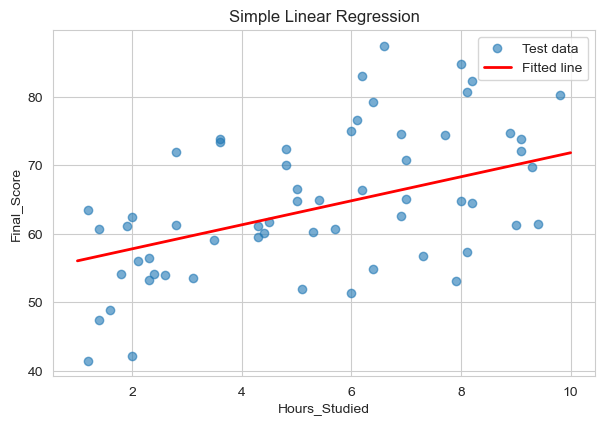

In [14]:
# Model 1, Simple Linear Regression
Xs_train, Xs_test = X_train[["Hours_Studied"]], X_test[["Hours_Studied"]]

slr = LinearRegression().fit(Xs_train, y_train)
print(f"Intercept = {slr.intercept_:.2f}, Slope = {slr.coef_[0]:.2f}")
evaluate("1. Simple Linear", slr, Xs_train, Xs_test)

xs = np.linspace(1, 10, 100).reshape(-1, 1)
xs_df = pd.DataFrame(xs, columns=["Hours_Studied"])
plt.scatter(Xs_test, y_test, alpha=0.6, label="Test data")
plt.plot(xs, slr.predict(xs_df), color="red", lw=2, label="Fitted line")
plt.xlabel("Hours_Studied"); plt.ylabel("Final_Score")
plt.title("Simple Linear Regression"); plt.legend()
plt.show()

Intercept: 1.32
Hours_Studied     1.833
Attendance_Pct    0.268
Previous_Score    0.348
Sleep_Hours       0.748
Practice_Tests    1.016
dtype: float64
2. Multiple Linear
  Train R2 = 0.859 | Test R2 = 0.910 | MAE = 2.49 | RMSE = 3.13


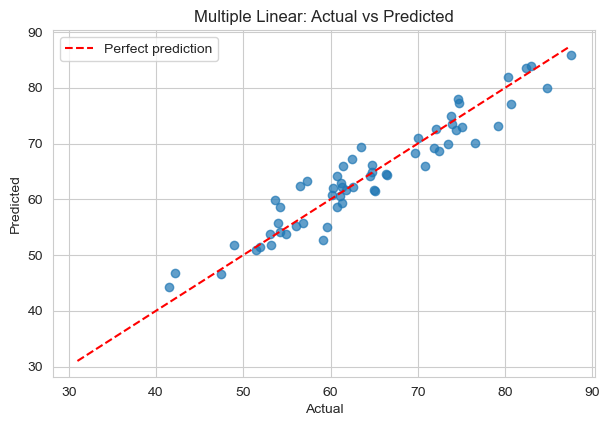

In [15]:
# Model 2, Multiple Linear Regression
mlr = LinearRegression().fit(X_train, y_train)
print("Intercept:", round(mlr.intercept_, 2))
print(pd.Series(mlr.coef_, index=features).round(3))
evaluate("2. Multiple Linear", mlr, X_train, X_test)

pred = mlr.predict(X_test)
plt.scatter(y_test, pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Perfect prediction")
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.title("Multiple Linear: Actual vs Predicted"); plt.legend()
plt.show()

   Degree  Train R2  Test R2
0       1     0.859    0.910
1       2     0.889    0.937
2       3     0.902    0.929
3       4     0.943    0.815
4       5     1.000   -9.097
5       6     1.000   -3.217
6       7     1.000   -3.150
7       8     1.000   -3.743


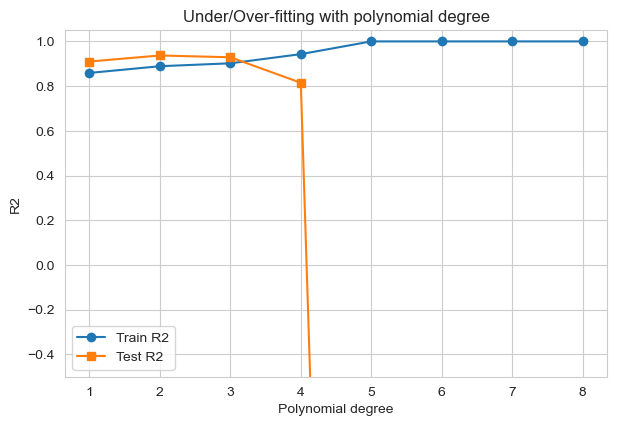

In [16]:
# Polynomial Regression (find the best degree)
rows = []
for d in range(1, 9):
    m = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression()).fit(X_train, y_train)
    rows.append((d, r2_score(y_train, m.predict(X_train)), r2_score(y_test, m.predict(X_test))))
deg_df = pd.DataFrame(rows, columns=["Degree", "Train R2", "Test R2"]).round(3)
print(deg_df)

plt.plot(deg_df["Degree"], deg_df["Train R2"], "o-", label="Train R2")
plt.plot(deg_df["Degree"], deg_df["Test R2"], "s-", label="Test R2")
plt.ylim(-0.5, 1.05)
plt.xlabel("Polynomial degree"); plt.ylabel("R2")
plt.title("Under/Over-fitting with polynomial degree"); plt.legend()
plt.show()

3. Polynomial (deg 2)
  Train R2 = 0.889 | Test R2 = 0.937 | MAE = 2.00 | RMSE = 2.62


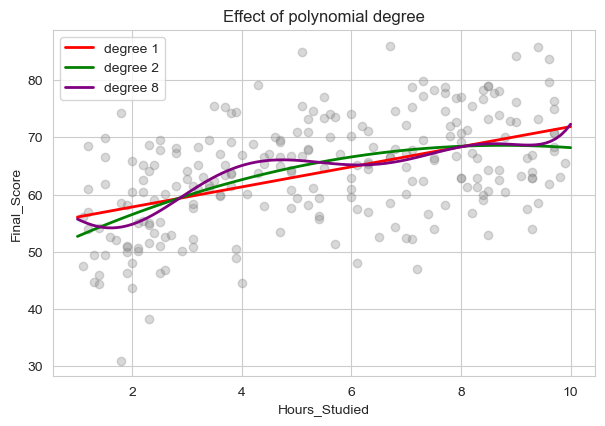

In [17]:
# Polynomial degree 2 (final model)
poly = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()).fit(X_train, y_train)
evaluate("3. Polynomial (deg 2)", poly, X_train, X_test)

for d, c in [(1, "red"), (2, "green"), (8, "purple")]:
    m = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(Xs_train, y_train)
    plt.plot(xs, m.predict(xs_df), color=c, lw=2, label=f"degree {d}")
plt.scatter(Xs_train, y_train, alpha=0.3, color="gray")
plt.xlabel("Hours_Studied"); plt.ylabel("Final_Score")
plt.title("Effect of polynomial degree"); plt.legend()
plt.show()

In [18]:
# Model 4, Support Vector Regression
svr_pipe = make_pipeline(StandardScaler(), SVR())
param_grid = {
    "svr__kernel": ["linear", "rbf"],
    "svr__C": [1, 10, 100],
    "svr__epsilon": [0.1, 1],
    "svr__gamma": ["scale", 0.05],
}
gs = GridSearchCV(svr_pipe, param_grid, cv=5, scoring="r2", n_jobs=-1).fit(X_train, y_train)
print("Best parameters:", gs.best_params_)
print(f"Best CV R2: {gs.best_score_:.3f}")
svr = gs.best_estimator_
evaluate("4. SVR (tuned)", svr, X_train, X_test)

Best parameters: {'svr__C': 1, 'svr__epsilon': 1, 'svr__gamma': 'scale', 'svr__kernel': 'linear'}
Best CV R2: 0.839
4. SVR (tuned)
  Train R2 = 0.856 | Test R2 = 0.906 | MAE = 2.48 | RMSE = 3.20


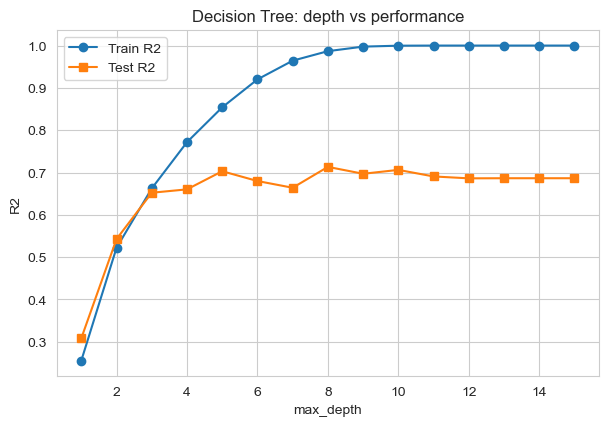

In [19]:
## Model 5, Decision Tree (depth experiment)
rows = []
for d in range(1, 16):
    m = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append((d, r2_score(y_train, m.predict(X_train)), r2_score(y_test, m.predict(X_test))))
dt_df = pd.DataFrame(rows, columns=["max_depth", "Train R2", "Test R2"])

plt.plot(dt_df["max_depth"], dt_df["Train R2"], "o-", label="Train R2")
plt.plot(dt_df["max_depth"], dt_df["Test R2"], "s-", label="Test R2")
plt.xlabel("max_depth"); plt.ylabel("R2")
plt.title("Decision Tree: depth vs performance"); plt.legend()
plt.show()

5a. Decision Tree (no limit)
  Train R2 = 1.000 | Test R2 = 0.687 | MAE = 4.62 | RMSE = 5.85
5b. Decision Tree (depth 4)
  Train R2 = 0.753 | Test R2 = 0.676 | MAE = 4.75 | RMSE = 5.94


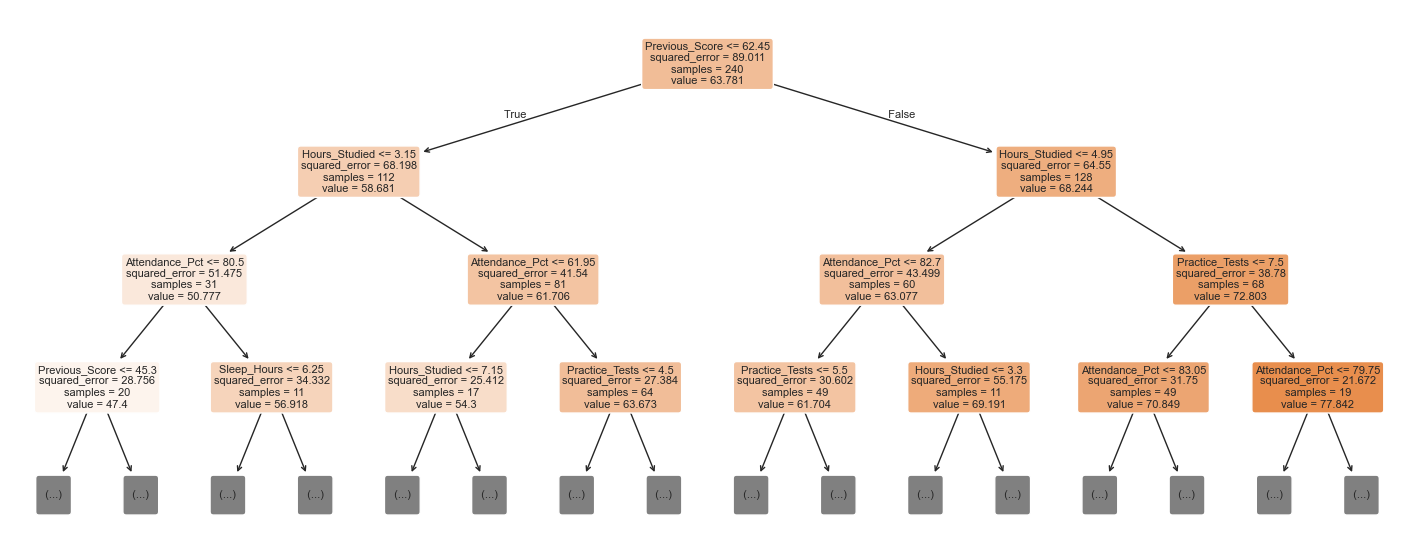

In [20]:
## Decision Tree (final models)
dt_unlimited = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train, y_train)
evaluate("5a. Decision Tree (no limit)", dt_unlimited, X_train, X_test)

dt = DecisionTreeRegressor(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE).fit(X_train, y_train)
evaluate("5b. Decision Tree (depth 4)", dt, X_train, X_test)

plt.figure(figsize=(18, 7))
plot_tree(dt, feature_names=features, filled=True, rounded=True, max_depth=3, fontsize=8)
plt.show()

6. Random Forest
  Train R2 = 0.925 | Test R2 = 0.861 | MAE = 2.99 | RMSE = 3.90


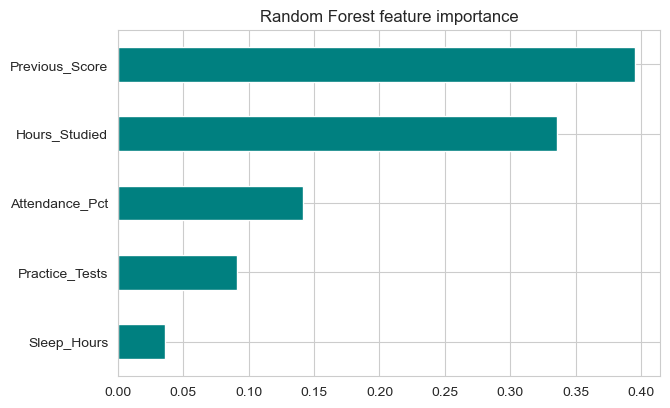

In [21]:
# Model 6, Random Forest
rf = RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=3,
                           random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
evaluate("6. Random Forest", rf, X_train, X_test)

pd.Series(rf.feature_importances_, index=features).sort_values().plot(kind="barh", color="teal")
plt.title("Random Forest feature importance")
plt.show()

In [22]:
# Model 7, Ridge and Lasso (regularization)
def poly_model(reg):
    return make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), reg)

plain = poly_model(LinearRegression()).fit(X_train, y_train)
evaluate("7a. Poly deg3 (no regularization)", plain, X_train, X_test)

ridge = poly_model(Ridge(alpha=10)).fit(X_train, y_train)
evaluate("7b. Ridge (alpha=10)", ridge, X_train, X_test)

lasso = poly_model(Lasso(alpha=0.1, max_iter=20000)).fit(X_train, y_train)
evaluate("7c. Lasso (alpha=0.1)", lasso, X_train, X_test)

n_zero = np.sum(lasso[-1].coef_ == 0)
print(f"\nLasso set {n_zero} of {len(lasso[-1].coef_)} coefficients to exactly 0")

7a. Poly deg3 (no regularization)
  Train R2 = 0.902 | Test R2 = 0.929 | MAE = 2.23 | RMSE = 2.79
7b. Ridge (alpha=10)
  Train R2 = 0.874 | Test R2 = 0.925 | MAE = 2.36 | RMSE = 2.87
7c. Lasso (alpha=0.1)
  Train R2 = 0.868 | Test R2 = 0.912 | MAE = 2.55 | RMSE = 3.10

Lasso set 39 of 55 coefficients to exactly 0


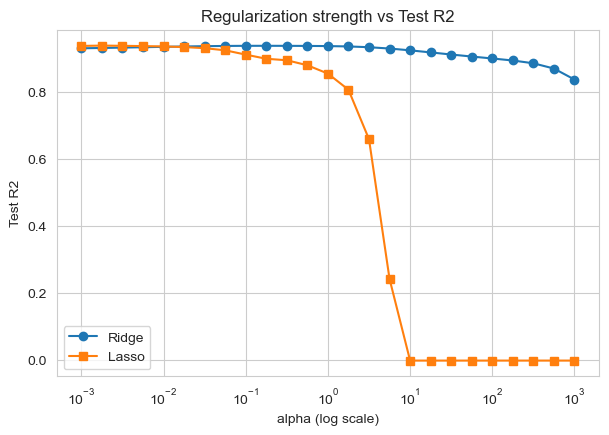

In [23]:
# Effect of alpha
alphas = np.logspace(-3, 3, 25)
r_test, l_test = [], []
for a in alphas:
    r_test.append(r2_score(y_test, poly_model(Ridge(alpha=a)).fit(X_train, y_train).predict(X_test)))
    l_test.append(r2_score(y_test, poly_model(Lasso(alpha=a, max_iter=20000)).fit(X_train, y_train).predict(X_test)))

plt.semilogx(alphas, r_test, "o-", label="Ridge")
plt.semilogx(alphas, l_test, "s-", label="Lasso")
plt.xlabel("alpha (log scale)"); plt.ylabel("Test R2")
plt.title("Regularization strength vs Test R2"); plt.legend()
plt.show()

                  OLS  Ridge  Lasso
Hours_Studied   4.798  3.940  3.707
Attendance_Pct  3.790  2.955  2.525
Previous_Score  6.249  5.023  4.957
Sleep_Hours     1.093  0.823  0.000
Practice_Tests  3.285  2.663  2.216


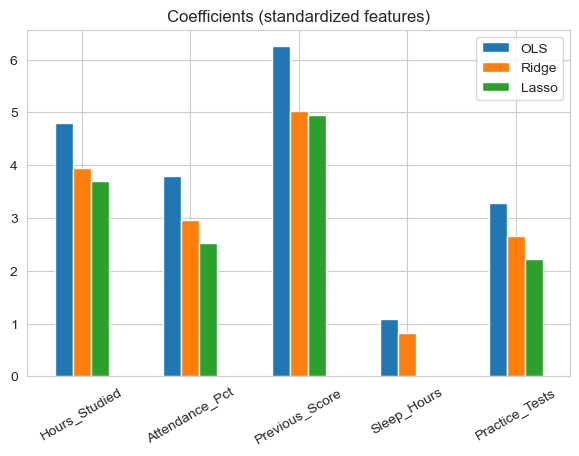

In [24]:
# Coefficient comparison (OLS vs Ridge vs Lasso)
Xtr_s = StandardScaler().fit(X_train).transform(X_train)
coefs = pd.DataFrame({
    "OLS":   LinearRegression().fit(Xtr_s, y_train).coef_,
    "Ridge": Ridge(alpha=50).fit(Xtr_s, y_train).coef_,
    "Lasso": Lasso(alpha=1.0).fit(Xtr_s, y_train).coef_,
}, index=features).round(3)
print(coefs)
coefs.plot(kind="bar")
plt.title("Coefficients (standardized features)")
plt.xticks(rotation=30)
plt.show()

In [25]:
# Model 8, Neural Network (corrected, with scaled X and y)
def make_nn(hidden=(8,)):
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            MLPRegressor(hidden_layer_sizes=hidden, activation="relu", solver="lbfgs",
                         alpha=0.1, max_iter=5000, random_state=RANDOM_STATE)),
        transformer=StandardScaler())

nn = make_nn().fit(X_train, y_train)
evaluate("8. Neural Network (8 neurons)", nn, X_train, X_test)

for h in [(4,), (8,), (32, 16), (128, 64, 32)]:
    m = make_nn(h).fit(X_train, y_train)
    print(f"hidden layers {str(h):>14} -> Train R2 = {r2_score(y_train, m.predict(X_train)):.3f} "
          f"| Test R2 = {r2_score(y_test, m.predict(X_test)):.3f}")

8. Neural Network (8 neurons)
  Train R2 = 0.898 | Test R2 = 0.914 | MAE = 2.28 | RMSE = 3.06
hidden layers           (4,) -> Train R2 = 0.896 | Test R2 = 0.939
hidden layers           (8,) -> Train R2 = 0.898 | Test R2 = 0.914
hidden layers       (32, 16) -> Train R2 = 0.997 | Test R2 = 0.861
hidden layers  (128, 64, 32) -> Train R2 = 1.000 | Test R2 = 0.873


,Train R2,Test R2,Test MAE,Test MSE,Test RMSE
Model,,,,,
3. Polynomial (deg 2),0.889,0.937,1.995,6.883,2.624
7a. Poly deg3 (no regularization),0.902,0.929,2.234,7.792,2.791
7b. Ridge (alpha=10),0.874,0.925,2.364,8.234,2.870
8. Neural Network (8 neurons),0.898,0.914,2.281,9.337,3.056
7c. Lasso (alpha=0.1),0.868,0.912,2.546,9.626,3.103
2. Multiple Linear,0.859,0.910,2.493,9.791,3.129
4. SVR (tuned),0.856,0.906,2.476,10.231,3.199
6. Random Forest,0.925,0.861,2.995,15.197,3.898
5a. Decision Tree (no limit),1.000,0.687,4.623,34.189,5.847


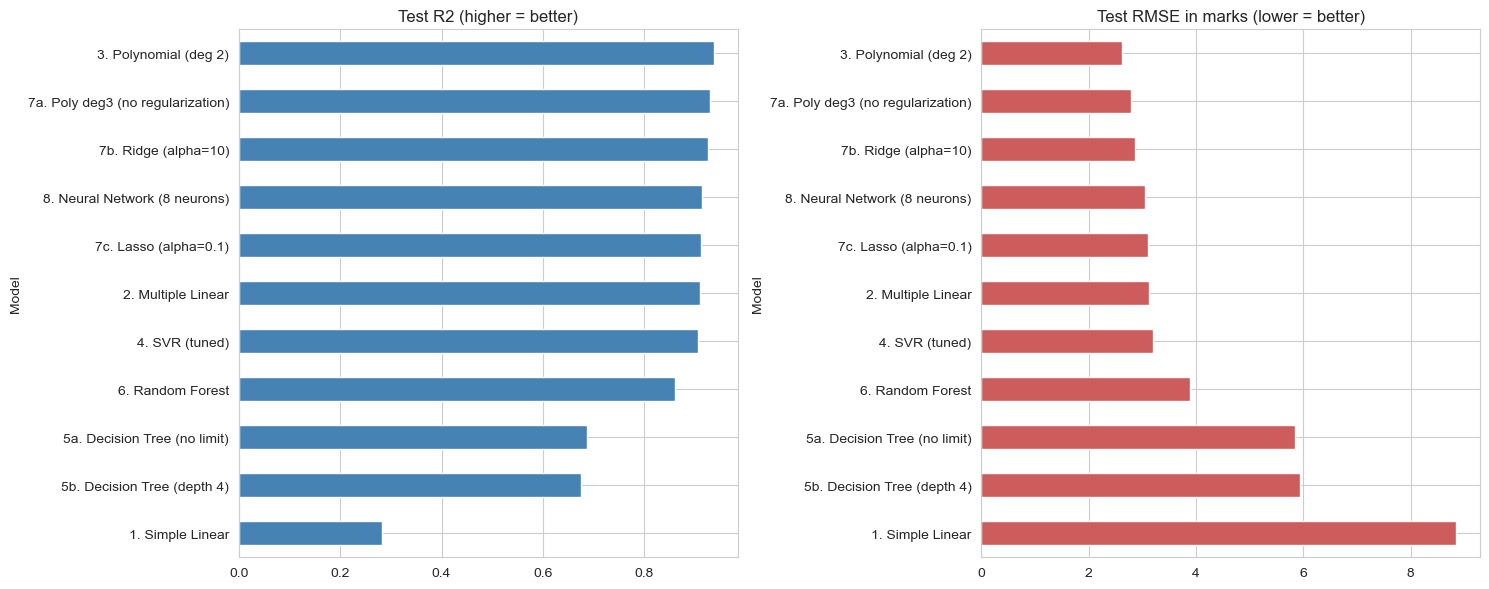

,Train R2,Test R2,Gap (Train-Test R2)
Model,,,
3. Polynomial (deg 2),0.889,0.937,-0.048
7a. Poly deg3 (no regularization),0.902,0.929,-0.027
7b. Ridge (alpha=10),0.874,0.925,-0.051
8. Neural Network (8 neurons),0.898,0.914,-0.016
7c. Lasso (alpha=0.1),0.868,0.912,-0.044
2. Multiple Linear,0.859,0.910,-0.051
4. SVR (tuned),0.856,0.906,-0.050
6. Random Forest,0.925,0.861,0.064
5a. Decision Tree (no limit),1.000,0.687,0.313


In [26]:
# Model performance comparison
res = pd.DataFrame(results).set_index("Model").round(3).sort_values("Test R2", ascending=False)
display(res)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
res["Test R2"].sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Test R2 (higher = better)")
res["Test RMSE"].sort_values(ascending=False).plot(kind="barh", ax=axes[1], color="indianred")
axes[1].set_title("Test RMSE in marks (lower = better)")
plt.tight_layout()
plt.show()

res["Gap (Train-Test R2)"] = (res["Train R2"] - res["Test R2"]).round(3)
display(res[["Train R2", "Test R2", "Gap (Train-Test R2)"]])

,Mean CV R2,Std
Model,,
Polynomial deg 2,0.880,0.038
Ridge (poly3),0.867,0.043
Lasso (poly3),0.860,0.039
Multiple Linear,0.859,0.035
SVR,0.859,0.032
Neural Network,0.850,0.042
Random Forest,0.792,0.047
Decision Tree,0.592,0.126


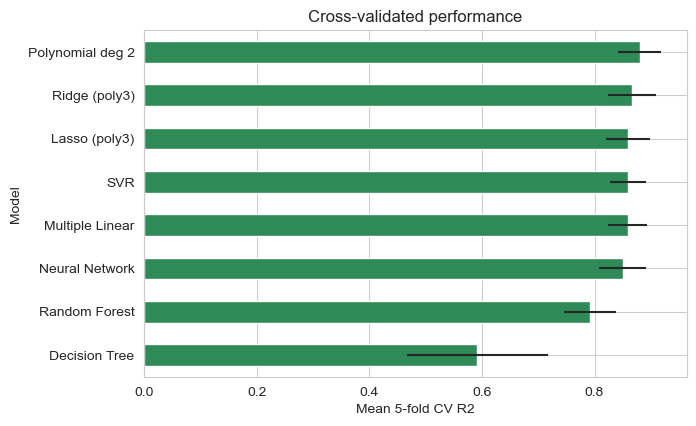

In [27]:
# Cross-validation
models = {
    "Multiple Linear":  LinearRegression(),
    "Polynomial deg 2": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    "Ridge (poly3)":    poly_model(Ridge(alpha=10)),
    "Lasso (poly3)":    poly_model(Lasso(alpha=0.1, max_iter=20000)),
    "SVR":              svr,
    "Decision Tree":    DecisionTreeRegressor(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random Forest":    RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_leaf=3,
                                              random_state=RANDOM_STATE, n_jobs=-1),
    "Neural Network":   make_nn(),
}
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=kf, scoring="r2")
    cv_rows.append((name, s.mean(), s.std()))

cv_df = (pd.DataFrame(cv_rows, columns=["Model", "Mean CV R2", "Std"])
           .set_index("Model").round(3).sort_values("Mean CV R2", ascending=False))
display(cv_df)

order = cv_df["Mean CV R2"].sort_values().index
cv_df.loc[order, "Mean CV R2"].plot(kind="barh", xerr=cv_df.loc[order, "Std"], color="seagreen")
plt.xlabel("Mean 5-fold CV R2")
plt.title("Cross-validated performance")
plt.show()

In [28]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)

res = pd.DataFrame(results).set_index("Model").round(3)
res = res.sort_values("Test R2", ascending=False)

# Add rank and fit status
res.insert(0, "Rank", range(1, len(res) + 1))
res["Gap (Train-Test R2)"] = (res["Train R2"] - res["Test R2"]).round(3)

def fit_status(row):
    if row["Test R2"] < 0.5:
        return "Underfit"
    if row["Gap (Train-Test R2)"] > 0.25:
        return "Overfit"
    if row["Gap (Train-Test R2)"] > 0.05:
        return "Slight overfit"
    return "Good fit"

res["Fit status"] = res.apply(fit_status, axis=1)
res

,Rank,Train R2,Test R2,Test MAE,Test MSE,Test RMSE,Gap (Train-Test R2),Fit status
Model,,,,,,,,
3. Polynomial (deg 2),1,0.889,0.937,1.995,6.883,2.624,-0.048,Good fit
7a. Poly deg3 (no regularization),2,0.902,0.929,2.234,7.792,2.791,-0.027,Good fit
7b. Ridge (alpha=10),3,0.874,0.925,2.364,8.234,2.870,-0.051,Good fit
8. Neural Network (8 neurons),4,0.898,0.914,2.281,9.337,3.056,-0.016,Good fit
7c. Lasso (alpha=0.1),5,0.868,0.912,2.546,9.626,3.103,-0.044,Good fit
2. Multiple Linear,6,0.859,0.910,2.493,9.791,3.129,-0.051,Good fit
4. SVR (tuned),7,0.856,0.906,2.476,10.231,3.199,-0.050,Good fit
6. Random Forest,8,0.925,0.861,2.995,15.197,3.898,0.064,Slight overfit
5a. Decision Tree (no limit),9,1.000,0.687,4.623,34.189,5.847,0.313,Overfit


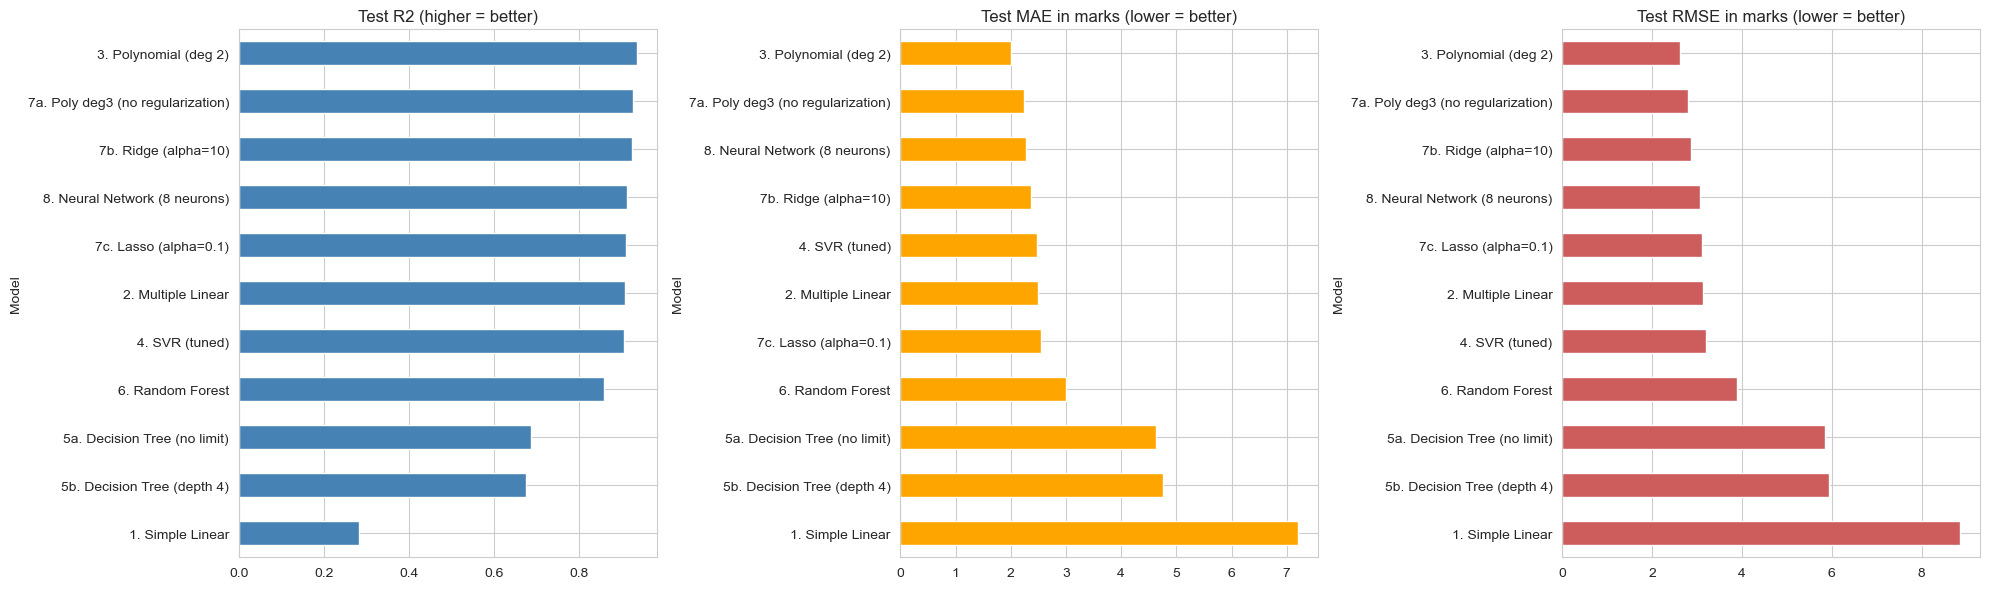

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

res["Test R2"].sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Test R2 (higher = better)")

res["Test MAE"].sort_values(ascending=False).plot(kind="barh", ax=axes[1], color="orange")
axes[1].set_title("Test MAE in marks (lower = better)")

res["Test RMSE"].sort_values(ascending=False).plot(kind="barh", ax=axes[2], color="indianred")
axes[2].set_title("Test RMSE in marks (lower = better)")

plt.tight_layout()
plt.show()

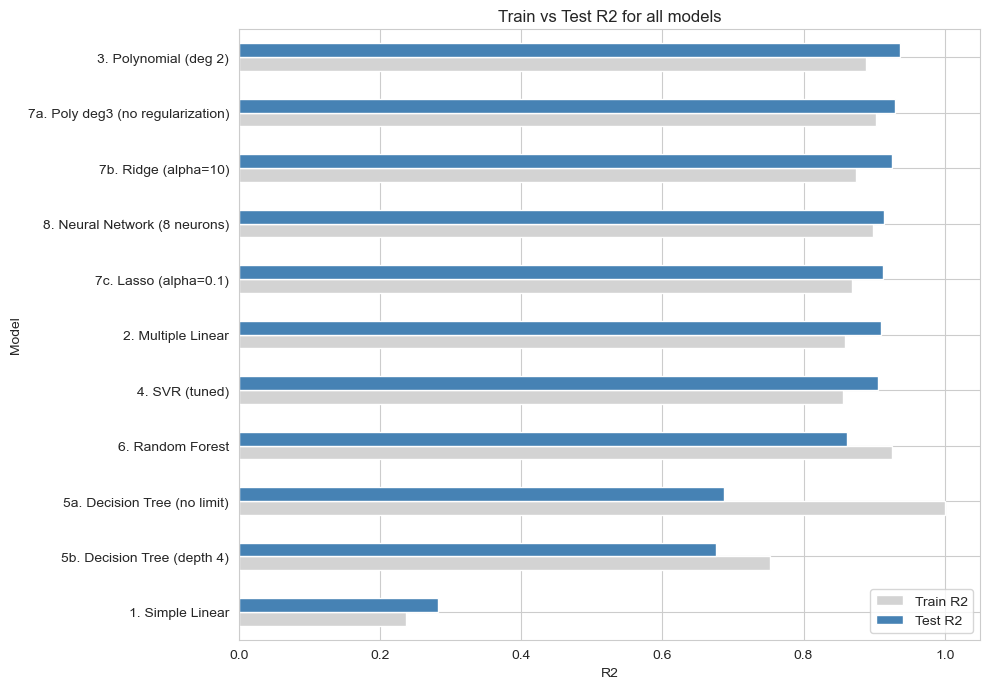

In [30]:
comp = res[["Train R2", "Test R2"]].iloc[::-1]
comp.plot(kind="barh", figsize=(10, 7), color=["lightgray", "steelblue"])
plt.xlabel("R2")
plt.title("Train vs Test R2 for all models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [32]:
with pd.ExcelWriter("model_performance_results.xlsx") as writer:
    res.to_excel(writer, sheet_name="Test performance")
    cv_df.to_excel(writer, sheet_name="Cross validation")
print("Saved: model_performance_results.xlsx")

Saved: model_performance_results.xlsx
